<a href="https://colab.research.google.com/github/Mehtabul-Islam/CSE427---Machine-Learning/blob/main/LAB%2005/Lab_05_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importing Necessary Libraries

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier as SklearnGBC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, log_loss)

import warnings
warnings.filterwarnings('ignore')

# Exploratory Data Analysis (EDA)

In [7]:
# read dataset from a public Google Drive File

file_link = 'https://drive.google.com/file/d/1T6M2YYrt5P-h36JYPnI4hBxnXqPih45v/view?usp=sharing'

# get the id part of the file
id = file_link.split("/")[-2]

# creating a new link using the id for better readability of csv file in pandas
new_link = f'https://drive.google.com/uc?id={id}'
df = pd.read_csv(new_link)

# let's look at the first few instances
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# Exploratory Data Analysis



In [8]:
print('Shape:', df.shape)
df.info()

Shape: (768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Target column: Outcome
Outcome
0    500
1    268
Name: count, dtype: int64


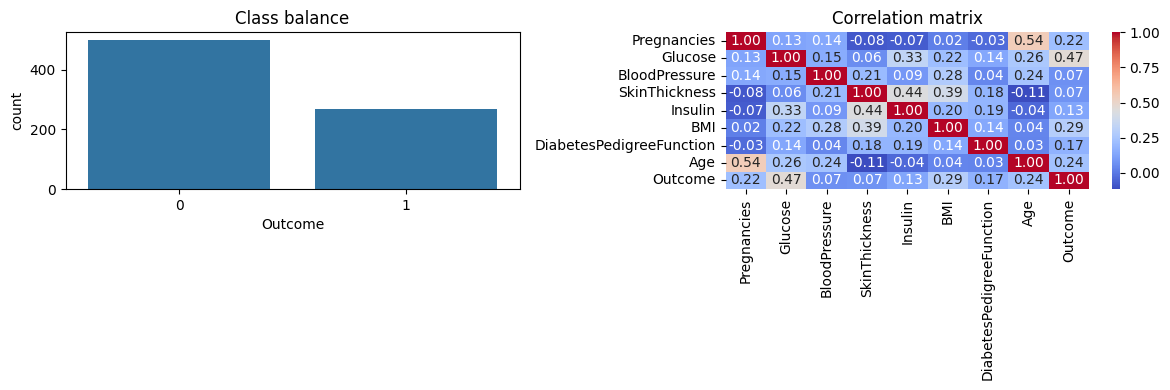

In [10]:
# Target column: 'Outcome' for the Pima dataset, otherwise the last column
TARGET = 'Outcome' if 'Outcome' in df.columns else df.columns[-1]
print('Target column:', TARGET)
print(df[TARGET].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=TARGET, data=df, ax=ax[0]); ax[0].set_title('Class balance')
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1])
ax[1].set_title('Correlation matrix')
plt.tight_layout(); plt.show()

# Data Preprocessing

In [11]:
print('Missing values:\n', df.isnull().sum(), '\n')
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Zeros that really mean "missing" (only applied to columns present in the data)
zero_as_missing = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
cols = [c for c in zero_as_missing if c in df.columns]
print('Zeros per column:\n', (df[cols] == 0).sum())
df[cols] = df[cols].replace(0, np.nan)

Missing values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64 

Duplicate rows: 0
Zeros per column:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [12]:
# Fill missing values in numerical features with column's mean value
columns_to_fill = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
    'BMI', 'DiabetesPedigreeFunction', 'Age']
df[columns_to_fill] = df[columns_to_fill].fillna(df[columns_to_fill].mean())
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


# Implementing Gradient Boosting using Scikit-learn

In [13]:
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
gb = SklearnGBC(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train, y_train)

y_pred = gb.predict(X_test)
y_prob = gb.predict_proba(X_test)[:, 1]

print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall   :', round(recall_score(y_test, y_pred), 4))
print('F1       :', round(f1_score(y_test, y_pred), 4))
print('ROC AUC  :', round(roc_auc_score(y_test, y_prob), 4))
print('Log loss :', round(log_loss(y_test, y_prob), 4))
print()
print(classification_report(y_test, y_pred))

Accuracy : 0.7338
Precision: 0.6129
Recall   : 0.6909
F1       : 0.6496
ROC AUC  : 0.8171
Log loss : 0.5394

              precision    recall  f1-score   support

           0       0.82      0.76      0.79        99
           1       0.61      0.69      0.65        55

    accuracy                           0.73       154
   macro avg       0.71      0.72      0.72       154
weighted avg       0.74      0.73      0.74       154



# Homework
# Implementing Gradient Boosting from Scratch
##Steps used in each boosting round:

1. Calculate the **logit** (starts as ln(odds) of y = 1)
2. Calculate the **probability** with the sigmoid
3. Calculate the **residual** = y − probability
4. Fit a **regression tree** with the residual as the target
5. Calculate the **leaf value** (transformation value) = Σ residual / Σ [p × (1 − p)]
6. Calculate the **new logit** (old logit + learning rate × leaf value), then the new probability and new residual
7. **Repeat the process until performance is better**

A decision tree needs to be generated first and then we move on to Gradient Boosting implementation

- **Standalone classifier:** split on the lowest SSR to retrive the leaf value for further calculation.

- **Inside gradient boosting:** the target is the residual, and the leaf value is the *transformation value* Σ residual / Σ [p(1−p)] (this needs the previous probabilities, passed in as `prob`).

# **Part 01**

In [14]:
class DecisionTree:
    def __init__(self, max_depth=None):
        self.max_depth = max_depth

    def leaf_value(self, y, prob):
        if prob is None:
            return y.mean()                                   # majority class (>= 0.5 -> 1)
        return y.sum() / (prob * (1 - prob)).sum()            # transformation value

    def fit(self, X, y, depth=0, prob=None):
        # leaf: all targets the same, max depth reached, or too few samples
        if len(np.unique(y)) == 1 or depth == self.max_depth or len(y) < 2:
            return {'leaf': True, 'value': self.leaf_value(y, prob)}

        # best feature and threshold using SSR
        best_feature, best_threshold = self.find_best_split(X, y)
        if best_feature is None:
            return {'leaf': True, 'value': self.leaf_value(y, prob)}

        # split the data
        left = X[:, best_feature] <= best_threshold
        right = ~left

        # build the tree recursively
        left_node = self.fit(X[left], y[left], depth + 1, None if prob is None else prob[left])
        right_node = self.fit(X[right], y[right], depth + 1, None if prob is None else prob[right])

        return {'leaf': False, 'feature': best_feature, 'threshold': best_threshold,
                'left': left_node, 'right': right_node}

    def find_best_split(self, X, y):
        best_feature, best_threshold, best_ssr = None, None, np.inf
        for feature in range(X.shape[1]):
            values = np.unique(X[:, feature])
            for threshold in (values[:-1] + values[1:]) / 2:    # midpoints between values
                left = X[:, feature] <= threshold
                y_left, y_right = y[left], y[~left]
                ssr = ((y_left - y_left.mean()) ** 2).sum() + ((y_right - y_right.mean()) ** 2).sum()
                if ssr < best_ssr:
                    best_feature, best_threshold, best_ssr = feature, threshold, ssr
        return best_feature, best_threshold

    def predict(self, node, x):
        if node['leaf']:
            return node['value']
        if x[node['feature']] <= node['threshold']:
            return self.predict(node['left'], x)
        return self.predict(node['right'], x)

# **Part 02**


In [15]:
def sigmoid(z):
    # complete the sigmoid function
    return 1 / (1 + np.exp(-z))


class GradientBoostingClassifier:
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3):
        # complete the initializations
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.trees = []              # list of (DecisionTree object, fitted tree)
        self.train_loss = []

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)

        p1 = y.mean()
        self.initial_logit = np.log(p1 / (1 - p1))
        logit = np.full(len(y), self.initial_logit)

        for _ in range(self.n_estimators):
            prob = sigmoid(logit)                 # probability
            residual = y - prob                   # residual

            tree = DecisionTree(max_depth=self.max_depth)
            # fit a regression tree on the residuals
            node = tree.fit(X, residual, prob=prob)

            # predictions of the weak learner -> update the logit
            update = np.array([tree.predict(node, x) for x in X])
            logit += self.learning_rate * update

            self.trees.append((tree, node))
            p_new = np.clip(sigmoid(logit), 1e-12, 1 - 1e-12)
            self.train_loss.append(-np.mean(y * np.log(p_new) + (1 - y) * np.log(1 - p_new)))

    def predict_proba(self, X):
        X = np.asarray(X)
        logit = np.full(len(X), self.initial_logit)
        for tree, node in self.trees:
            logit += self.learning_rate * np.array([tree.predict(node, x) for x in X])
        return sigmoid(logit)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

In [16]:
# Gradient Boosting
gb_classifier = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)
gb_classifier.fit(X_train, y_train)
gb_predictions = gb_classifier.predict(X_test)
y_prob_s = gb_classifier.predict_proba(X_test)

gb_accuracy = (gb_predictions == y_test.to_numpy()).sum() / len(y_test)
print("Gradient Boosting (from scratch) Accuracy:", round(gb_accuracy, 4))

Gradient Boosting (from scratch) Accuracy: 0.7403
